In [11]:

import os
import random
import json
import pandas as pd
import numpy as np
import cv2
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter
import matplotlib.patches as patches

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔧 Using device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")




🔧 Using device: cuda
   GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [12]:
BASE_DIR = '.'
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")
df_sample_submission = pd.read_csv("sample_submission.csv")

# EDA

Number of training images in COCO: 750
Number of annotations: 1509
Categories: ['Images', 'entete', 'vin']
Annotation counts per category:
  vin: 755
  entete: 754


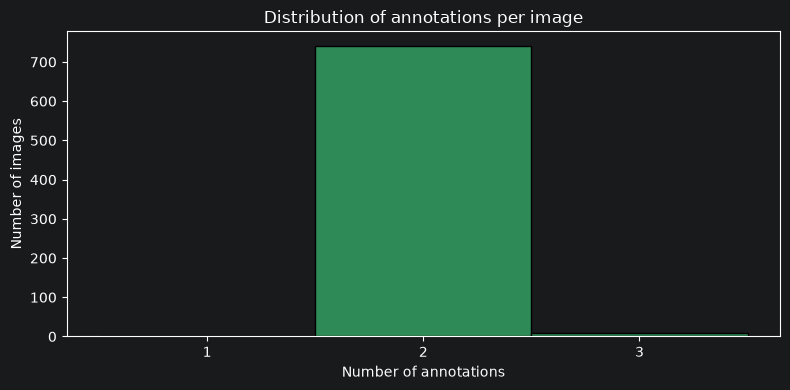

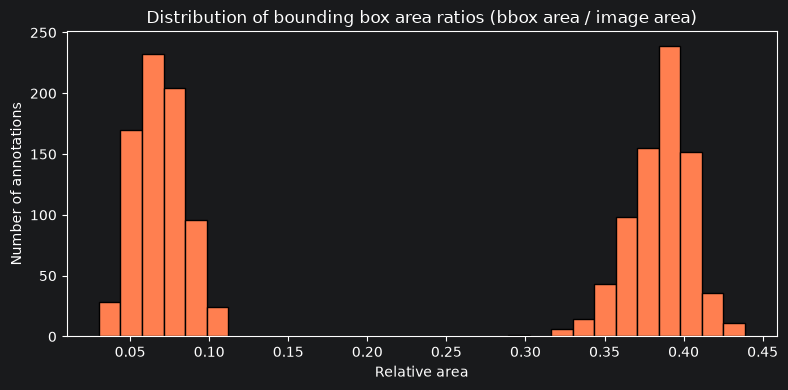

In [13]:
# Load COCO annotations for bounding boxes
annotations_path = os.path.join(BASE_DIR, 'train', '_annotations.coco.json')
with open(annotations_path, 'r', encoding='utf-8') as f:
    coco = json.load(f)

images = coco['images']
annotations = coco['annotations']
categories = coco['categories']

print(f'Number of training images in COCO: {len(images)}')
print(f'Number of annotations: {len(annotations)}')
print('Categories:', [cat['name'] for cat in categories])

category_counts = Counter()
annotations_per_image = Counter()
area_ratios = []
image_dim = {img['id']: (img['width'], img['height']) for img in images}

for ann in annotations:
    category_counts[ann['category_id']] += 1
    annotations_per_image[ann['image_id']] += 1
    bbox = ann['bbox']
    img_w, img_h = image_dim[ann['image_id']]
    area_ratios.append((bbox[2] * bbox[3]) / (img_w * img_h))

id_to_cat = {cat['id']: cat['name'] for cat in categories}
print('Annotation counts per category:')
for cat_id, count in category_counts.items():
    print(f'  {id_to_cat[cat_id]}: {count}')

# Plot distribution of annotations per image
plt.figure(figsize=(8,4))
plt.hist(list(annotations_per_image.values()), bins=range(1, max(annotations_per_image.values()) + 2),
         color='seagreen', edgecolor='black', align='left')
plt.title('Distribution of annotations per image')
plt.xlabel('Number of annotations')
plt.ylabel('Number of images')
plt.xticks(range(1, max(annotations_per_image.values()) + 1))
plt.tight_layout()
plt.show()

# Plot distribution of bounding box area ratios
plt.figure(figsize=(8,4))
plt.hist(area_ratios, bins=30, color='coral', edgecolor='black')
plt.title('Distribution of bounding box area ratios (bbox area / image area)')
plt.xlabel('Relative area')
plt.ylabel('Number of annotations')
plt.tight_layout()
plt.show()

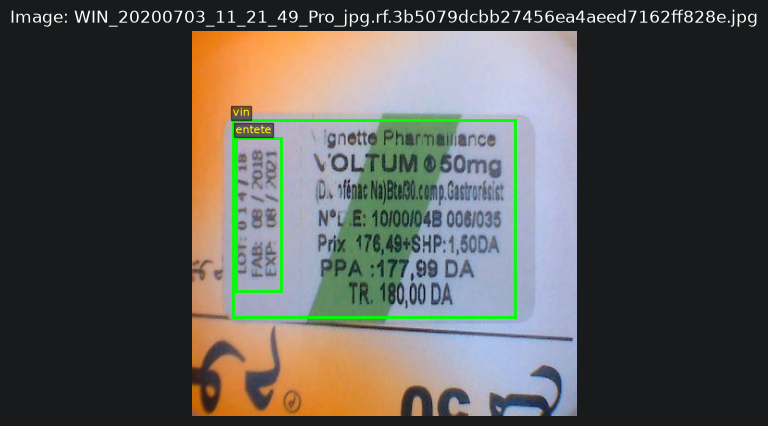

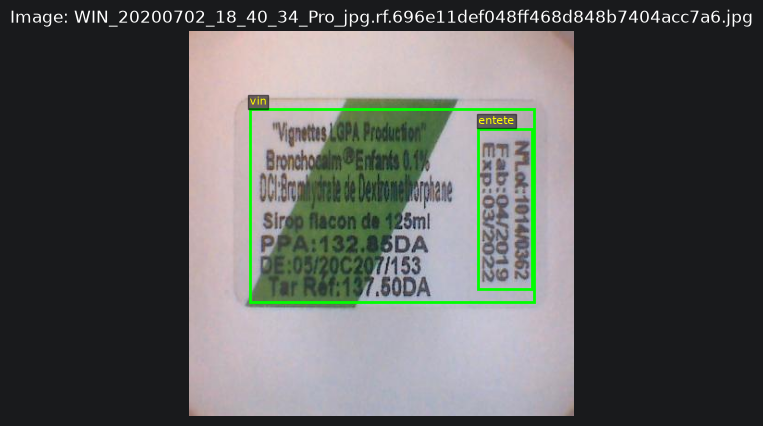

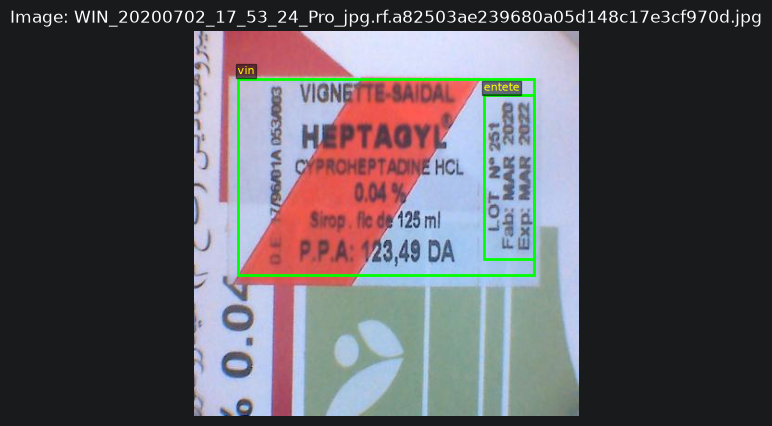

In [14]:
# Visualize random training images with bounding boxes
n_samples = 3
sample_images = random.sample(images, n_samples)

for img_info in sample_images:
    img_id = img_info['id']
    file_name = img_info['file_name']
    img_path = os.path.join(BASE_DIR, 'train', file_name)
    img = Image.open(img_path).convert('RGB')
    fig, ax = plt.subplots(1,1, figsize=(5,5))
    ax.imshow(img)
    for ann in annotations:
        if ann['image_id'] == img_id:
            bbox = ann['bbox']
            rect = patches.Rectangle((bbox[0], bbox[1]), bbox[2], bbox[3],
                                     linewidth=2, edgecolor='lime', facecolor='none')
            ax.add_patch(rect)
            cat_name = id_to_cat[ann['category_id']]
            ax.text(bbox[0], max(bbox[1] - 5, 0), cat_name, color='yellow', fontsize=8,
                    bbox=dict(facecolor='black', alpha=0.5, pad=1))
    ax.set_title(f'Image: {file_name}')
    ax.axis('off')
    plt.show()

8# STARTER

In [15]:
id_column = df_sample_submission.columns[0]
target_column = df_sample_submission.columns[1]

placeholder_text = 'recognized-text'.upper()
predictions = np.full(len(df_test), placeholder_text)

In [16]:
submission_df = pd.DataFrame({
    id_column: df_test[id_column], # Use the ID column from the test data
    target_column: predictions
})

# Crucially, save the file as 'submission.csv' to the working directory.
# The `index=False` argument is essential to prevent pandas from writing row numbers.
submission_df.to_csv('submission.csv', index=False)

print("\nSuccessfully created submission.csv!")
print("Submission Head:")
print(submission_df.head())


Successfully created submission.csv!
Submission Head:
                                     id             text
0  0016f1ad9e7f16aa6dd2b8c9c13cb922.jpg  RECOGNIZED-TEXT
1  005e28f75a93bc4de0e9e11373bdca47.jpg  RECOGNIZED-TEXT
2  007f7b00eb0a66cabcd72007358e3660.jpg  RECOGNIZED-TEXT
3  009a43c2870949af417f769b90ee20cf.jpg  RECOGNIZED-TEXT
4  014d3d8a2ef0d4deb88a83357781745c.jpg  RECOGNIZED-TEXT


# BASELINE PROTOKOL

In [17]:
import argparse
import json
import random
import re
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

TS_RE = re.compile(r"WIN_(\d{8})_(\d{2})_(\d{2})_(\d{2})")

In [18]:

def parse_ts(name):
    """'WIN_20200702_14_56_08_Pro...' -> datetime; None jika pola tidak cocok."""
    m = TS_RE.search(name)
    return datetime.strptime("".join(m.groups()), "%Y%m%d%H%M%S") if m else None


def largest(boxes):
    """Dari beberapa kotak [x, y, w, h], ambil yang terluas (None jika kosong)."""
    return max(boxes, key=lambda b: b[2] * b[3]) if boxes else None


def load_coco(path):
    coco = json.load(open(annotations_path, encoding="utf-8"))
    cat_name = {c["id"]: c["name"] for c in coco["categories"]}  # petakan per NAMA, bukan indeks
    per_img = {}
    for a in coco["annotations"]:
        per_img.setdefault(a["image_id"], {}).setdefault(cat_name[a["category_id"]], []).append(a["bbox"])
    rows = []
    for im in coco["images"]:
        boxes = per_img.get(im["id"], {})
        rows.append(dict(
            image_id=im["id"], file_name=im["file_name"], width=im["width"], height=im["height"],
            ts=parse_ts(im["file_name"]),
            n_entete=len(boxes.get("entete", [])),
            entete=largest(boxes.get("entete", [])), vin=largest(boxes.get("vin", [])),
        ))
    return pd.DataFrame(rows)


def blocked_split(df, block_size=30, val_frac=0.2, seed=42):
    """
    Urutkan menurut waktu, potong jadi blok berurutan, lalu acak PER BLOK.
    Frame yang berdekatan waktunya selalu masuk split yang sama -> mengurangi kebocoran.
    """
    df = df.sort_values(["ts", "file_name"], na_position="first").reset_index(drop=True)
    df["block"] = np.arange(len(df)) // block_size
    blocks = sorted(df["block"].unique())
    val_blocks = set(random.Random(seed).sample(blocks, max(1, round(len(blocks) * val_frac))))
    df["split"] = np.where(df["block"].isin(val_blocks), "val", "train")
    return df


def crop_box(img, box, pad=0.08):
    """Potong kotak [x, y, w, h] dengan padding relatif; jika tegak, putar 90 deg agar horizontal."""
    H, W = img.shape[:2]
    x, y, w, h = box
    x1, y1 = max(0, int(x - pad * w)), max(0, int(y - pad * h))
    x2, y2 = min(W, int(x + w + pad * w)), min(H, int(y + h + pad * h))
    crop = img[y1:y2, x1:x2]
    if crop.shape[0] > crop.shape[1]:
        crop = np.ascontiguousarray(np.rot90(crop))
    return crop


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--coco", required=True)
    ap.add_argument("--images_dir", default=None, help="default: folder file COCO")
    ap.add_argument("--out_dir", required=True)
    ap.add_argument("--block_size", type=int, default=30)
    ap.add_argument("--val_frac", type=float, default=0.2)
    ap.add_argument("--n_gold", type=int, default=80)
    ap.add_argument("--seed", type=int, default=42)
    a = ap.parse_args(argv)

    images_dir = Path(a.images_dir) if a.images_dir else Path(a.coco).parent
    out = Path(a.out_dir)
    (out / "crops").mkdir(parents=True, exist_ok=True)

    df = blocked_split(load_coco(a.coco), a.block_size, a.val_frac, a.seed)

    crop_paths = []
    for r in df.itertuples():
        img = cv2.imread(str(images_dir / r.file_name))
        if img is None or r.entete is None:        # catat, jangan hilang diam-diam
            crop_paths.append("")
            continue
        p = out / "crops" / (Path(r.file_name).stem + ".png")
        cv2.imwrite(str(p), crop_box(img, r.entete))
        crop_paths.append(str(p))
    df["crop_path"] = crop_paths
    df.to_csv(out / "meta.csv", index=False)

    val = df[(df["split"] == "val") & (df["crop_path"] != "")]
    gold = val.sample(min(a.n_gold, len(val)), random_state=a.seed)[["file_name", "crop_path"]]
    gold = gold.rename(columns={"file_name": "id"}).assign(verified_text="")
    gold.to_csv(out / "gold_candidates.csv", index=False)

    print(df.groupby("split").size().to_string())
    print("gambar tanpa entete:", int((df["entete"].isna()).sum()),
          "| gambar dengan >1 entete:", int((df["n_entete"] > 1).sum()),
          "| crop gagal:", int((df["crop_path"] == "").sum()))
    print("gold candidates:", len(gold))

import phase0_prepare as p
p.main(["--coco", "train/_annotations.coco.json", "--out_dir", "phase0"])


split
train    600
val      150
gambar tanpa entete: 0 | gambar dengan >1 entete: 4 | crop gagal: 0
gold candidates: 80


# EASYOCR LANGSUNG (TANPA DETEKTOR)

Gambar test tidak punya anotasi kotak, jadi EasyOCR dijalankan pada **seluruh gambar**, lalu satu teks dipilih per gambar dengan heuristik (lihat sel pemilihan).
Hasil mentah OCR disimpan ke `ocr_raw.json`, sehingga aturan pemilihan bisa disetel ulang tanpa mengulang OCR.

In [19]:
# 1) Pasang & muat EasyOCR (torch + CUDA sudah tersedia di notebook ini)
try:
    import easyocr
except ImportError:
    %pip install -q easyocr
    import easyocr

import re, time

ALLOWLIST = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789/-'   # sesuai aturan format submission
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available())

# 2) Cari folder gambar test, lalu petakan nama file -> path
TEST_DIR = next((os.path.join(BASE_DIR, d) for d in ['test', 'Test', os.path.join('images', 'test')]
                 if os.path.isdir(os.path.join(BASE_DIR, d))), None)
assert TEST_DIR is not None, "Folder gambar test tidak ditemukan. Atur TEST_DIR secara manual."

path_of = {}
for root, _, files in os.walk(TEST_DIR):
    for fn in files:
        path_of[fn] = os.path.join(root, fn)

ids = df_test[id_column].tolist()
missing = [i for i in ids if i not in path_of]
print(f"Folder test : {TEST_DIR}")
print(f"Jumlah id   : {len(ids)} | gambar tidak ditemukan: {len(missing)}")
if missing:
    print("Contoh id hilang:", missing[:5])

Folder test : .\test
Jumlah id   : 674 | gambar tidak ditemukan: 0


In [20]:
# 3) Jalankan EasyOCR pada semua gambar test (hasil di-cache, aman jika notebook terhenti)
RAW_PATH   = 'ocr_raw.json'
ROTATIONS  = [90, 270]     # ikut membaca teks tegak (baseline juga memutar crop tegak). Set [] agar lebih cepat.

raw = json.load(open(RAW_PATH, encoding='utf-8')) if os.path.exists(RAW_PATH) else {}
todo = [i for i in ids if i not in raw]
print(f"Sudah di-cache: {len(raw)} | akan diproses: {len(todo)}")

t0 = time.time()
for n, img_id in enumerate(tqdm(todo), 1):
    img = cv2.imread(path_of[img_id]) if img_id in path_of else None
    if img is None:
        raw[img_id] = []
    else:
        try:
            res = reader.readtext(img, allowlist=ALLOWLIST, rotation_info=ROTATIONS,
                                  detail=1, paragraph=False)
        except Exception as e:
            print(f"[gagal] {img_id}: {e}")
            res = []
        raw[img_id] = [dict(box=[[int(x), int(y)] for x, y in b], text=t, conf=float(c))
                       for b, t, c in res]
    if n % 50 == 0:
        json.dump(raw, open(RAW_PATH, 'w', encoding='utf-8'))

json.dump(raw, open(RAW_PATH, 'w', encoding='utf-8'))
print(f"Selesai dalam {time.time() - t0:.0f} detik")

Sudah di-cache: 0 | akan diproses: 674


100%|██████████| 674/674 [16:54<00:00,  1.50s/it]

Selesai dalam 1014 detik


In [21]:
# 4) Pilih satu teks per gambar & bentuk submission.csv
_DASH  = str.maketrans({'–': '-', '—': '-', '‒': '-', '−': '-', '_': '-', '\\': '/'})
_VALID = re.compile(r'[^A-Z0-9/-]')

def clean_text(s):
    """Huruf besar, hanya A-Z, 0-9, '/' dan '-'; semua spasi/baris baru hilang."""
    return _VALID.sub('', s.translate(_DASH).upper())

def to_items(dets):
    items = []
    for d in dets:
        xs = [p[0] for p in d['box']]; ys = [p[1] for p in d['box']]
        x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
        w, h = x2 - x1, y2 - y1
        txt = clean_text(d['text'])
        items.append(dict(x1=x1, x2=x2, y1=y1, y2=y2, w=w, h=h, cx=(x1 + x2) / 2, cy=(y1 + y2) / 2,
                          vertical=(h > 1.5 * w and len(txt) >= 2), text=txt, conf=d['conf']))
    return [it for it in items if it['text']]

def merge_lines(items, y_tol=0.6, gap_tol=2.5):
    """Gabungkan potongan teks horizontal yang sebaris (EasyOCR sering memecah 'A23B/45' dan '-C99')."""
    lines = []
    for it in sorted([i for i in items if not i['vertical']], key=lambda i: i['cy']):
        for ln in lines:
            cy = np.mean([m['cy'] for m in ln]); hh = max(it['h'], np.mean([m['h'] for m in ln]))
            gap = min(max(0, it['x1'] - m['x2'], m['x1'] - it['x2']) for m in ln)
            if abs(it['cy'] - cy) < y_tol * hh and gap < gap_tol * hh:
                ln.append(it); break
        else:
            lines.append([it])
    out = []
    for ln in lines:
        ln = sorted(ln, key=lambda m: m['x1'])
        wts = [len(m['text']) for m in ln]
        out.append(dict(text=''.join(m['text'] for m in ln),
                        conf=float(np.average([m['conf'] for m in ln], weights=wts))))
    # teks tegak: tiap deteksi diperlakukan sebagai satu baris sendiri
    out += [dict(text=i['text'], conf=i['conf']) for i in items if i['vertical']]
    return out

def score_line(ln):
    t = ln['text']
    if len(t.strip('/-')) < 3:
        return 0.0
    s = ln['conf'] * min(len(t), 20)
    if any(c.isdigit() for c in t) and any(c in '/-' for c in t):   # pola khas ID: ada angka + pemisah
        s *= 1.5
    return s

def predict_text(dets):
    lines = merge_lines(to_items(dets))
    best = max(lines, key=score_line, default=None)
    if best is not None and score_line(best) > 0:
        return best['text'].strip('/-') or '0'
    return '0'          # tidak ada teks terbaca -> isi aman agar baris tidak kosong

preds = [predict_text(raw.get(i, [])) for i in df_test[id_column]]
submission_df = pd.DataFrame({id_column: df_test[id_column], target_column: preds})

# Validasi format sesuai aturan lomba
assert submission_df[target_column].str.fullmatch(r'[A-Z0-9/-]+').all(), "Ada teks yang melanggar format"
assert submission_df[id_column].is_unique and len(submission_df) == len(df_test)

submission_df.to_csv('submission.csv', index=False)
print("submission.csv tersimpan:", submission_df.shape)
print("Gambar tanpa hasil OCR (diisi '0'):", int((submission_df[target_column] == '0').sum()))
print(submission_df.head(10).to_string(index=False))

submission.csv tersimpan: (674, 2)
Gambar tanpa hasil OCR (diisi '0'): 0
                                  id                          text
0016f1ad9e7f16aa6dd2b8c9c13cb922.jpg                     2357/29QA
005e28f75a93bc4de0e9e11373bdca47.jpg                  8/04B009/003
007f7b00eb0a66cabcd72007358e3660.jpg                   FABLOT17LM8
009a43c2870949af417f769b90ee20cf.jpg           SOLU-MEDROLO20M9/2M
014d3d8a2ef0d4deb88a83357781745c.jpg EURAPHARMADISTRIBUTIONVONETTE
0174f52895414f9f2b5842547803f533.jpg              1EE06883383333YG
02a45854f6bdaff85587d8017a344ff9.jpg                        11K185
02d5c041d5aebd133a34b7cb5e679557.jpg                   DE98/11H028
02ff1c092c2f1d483916e898ef740392.jpg           10PERH04-2024378111
0396159a179dc766efd00a86fa040f02.jpg                       ALGERIE


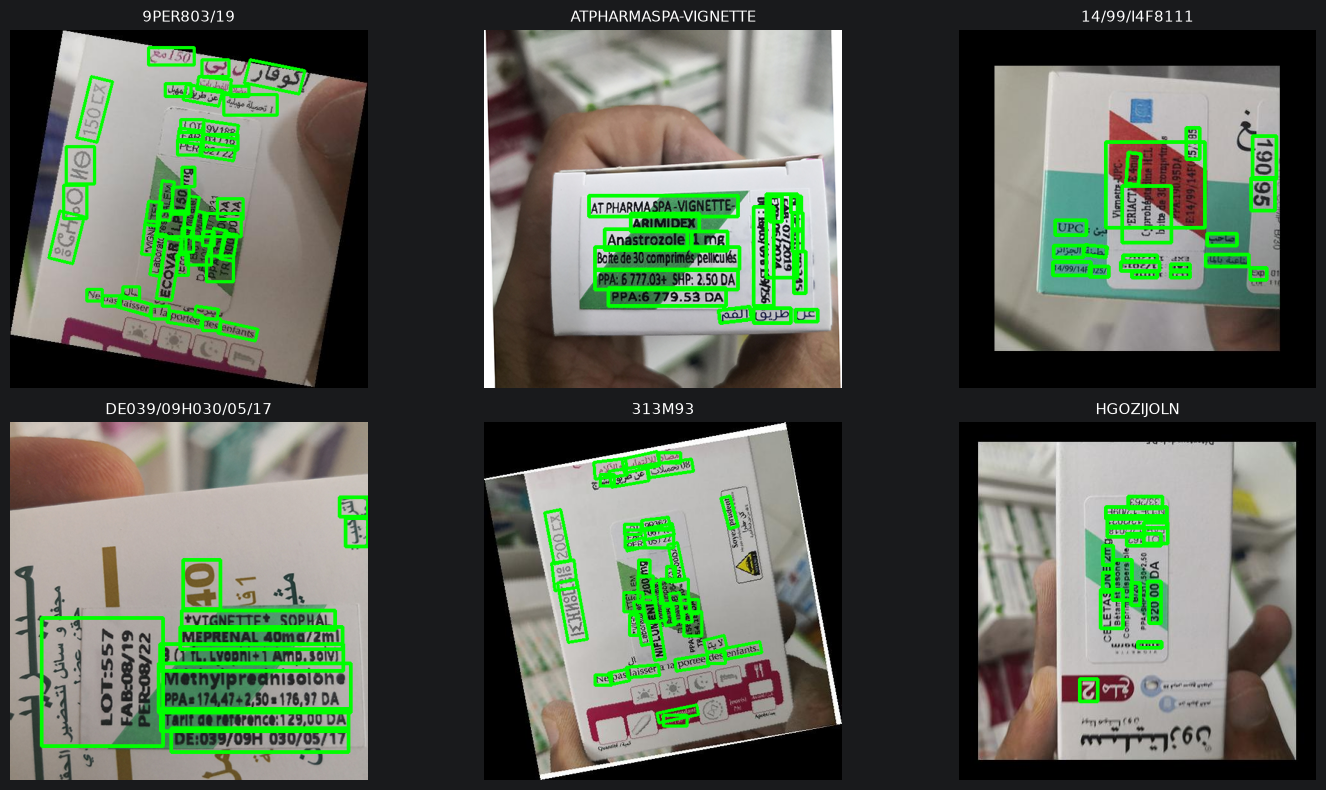

In [22]:
# 5) Cek visual cepat (tanpa label): kotak OCR + teks yang dipilih
sample_ids = random.sample(ids, min(6, len(ids)))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, img_id in zip(axes.ravel(), sample_ids):
    img = cv2.imread(path_of[img_id])
    if img is not None:
        for d in raw.get(img_id, []):
            pts = np.array(d['box'], dtype=np.int32)
            cv2.polylines(img, [pts], True, (0, 255, 0), 3)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(submission_df.loc[submission_df[id_column] == img_id, target_column].iat[0], fontsize=11)
    ax.axis('off')
plt.tight_layout(); plt.show()